In [ ]:
import csv
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from desmin_reconstruction.plotting import save_panel
from IPython.display import display, SVG
from matplotlib.lines import Line2D
from matplotlib.patches import Patch


PROTEINS = ("actin", "actinin", "myosin")

COLOR_DICT = {
    "desmin": "#CC3311",
    "actin": "#0077BB",
    "actinin": "#009988",
    "myosin": "#BBBBBB",
}
LABEL_DICT = {"actin": "Actin", "actinin": "α-actinin", "myosin": "Myosin"}


In [ ]:
def load_pearsons(csv_path):
    """Read named columns; reject missing/invalid observations rather than omit.

    Each column is treated as a separate group, matching the supplied analysis.
    No normalization, Fisher transformation, or rounding is applied.
    """
    values = {p: [] for p in PROTEINS}
    with Path(csv_path).open(newline="", encoding="utf-8-sig") as handle:
        reader = csv.DictReader(handle)
        missing = set(LABEL_DICT.values()) - set(reader.fieldnames or ())
        if missing:
            raise ValueError(f"CSV is missing columns: {sorted(missing)}")
        for row_number, row in enumerate(reader, start=2):
            for protein in PROTEINS:
                column = LABEL_DICT[protein]
                try:
                    value = float(row[column])
                except (ValueError, TypeError) as exc:
                    raise ValueError(
                        f"Row {row_number}, {column}: expected a numeric value."
                    ) from exc
                if not np.isfinite(value) or not -1 <= value <= 1:
                    raise ValueError(
                        f"Row {row_number}, {column}: Pearson r must be finite and in [-1, 1]."
                    )
                values[protein].append(value)
    values = {p: np.asarray(v, dtype=float) for p, v in values.items()}
    for protein, v in values.items():
        if v.size < 2 or np.ptp(v) == 0:
            raise ValueError(
                f"{LABEL_DICT[protein]} needs at least two observations with "
                "nonzero variance for this violin/Welch/Games-Howell workflow."
            )
    return values


def monte_carlo_upper_pvalues(observed, null):
    """Raw one-sided p-values, with exact ties included and Laplace correction.

    observed: (n_patches,); null: (n_patches, n_randomizations).
    All entries must be finite. No values are omitted or rounded before the
    comparison. Returns (p_values, exceedance_counts, n_randomizations).
    """
    observed = np.asarray(observed, dtype=float)
    null = np.asarray(null, dtype=float)
    if observed.ndim != 1 or observed.size == 0:
        raise ValueError("observed must be a nonempty 1D array.")
    if null.ndim != 2 or null.shape[0] != observed.size or null.shape[1] == 0:
        raise ValueError("null must have shape (n_patches, n_randomizations).")
    if not np.isfinite(observed).all() or not np.isfinite(null).all():
        raise ValueError("Observed and scrambled correlations must all be finite.")
    B = null.shape[1]
    b = np.count_nonzero(null >= observed[:, None], axis=1)
    return (b + 1) / (B + 1), b, B


def _format_pvalue(value, decimals):
    # Even for very large B, never round a positive p-value to '0.000'.
    threshold = 10.0 ** (-decimals)
    return (
        f"<{threshold:.{decimals}f}" if value < threshold else f"{value:.{decimals}f}"
    )


def plot_pearson_nulls(
    pearsons_scrambled_dict,
    results_dict,
    *,
    proteins=("actin", "actinin", "myosin"),
    colors=None,
    labels=None,
    figsize=(10, 6.5),
    font_family="DejaVu Sans",
    label_fontsize=14,
    tick_fontsize=12,
    row_title_fontsize=14,
    p_fontsize=9,
    p_decimals=3,
    significance_level=0.05,
    p_above_color="#C00000",
    p_other_color="#222222",
    p_y=1.08,
    row_title_pad=25,
    hspace=0.18,
    violin_width=0.55,
    violin_facecolor="#E6DDF0",
    violin_edgecolor="#9682AA",
    violin_linewidth=0.8,
    point_size=60,
    point_edgecolor="#222222",
    point_linewidth=1.0,
    point_halo_width=0.8,
    point_halo_color="white",
    bw_method=None,
):
    """Create the full figure and return (fig, axes, info).

    Each scrambled array must be (n_patches, B); it is transposed for
    Matplotlib so each patch gets its own violin. The measured array is
    results_dict[protein]['pearson'], with shape (n_patches,). Every protein
    must have the same number of patches for the shared X axis.

    Figure dimensions are inches; font sizes, line widths, and row_title_pad
    are points. point_size is marker area in points squared. p_y is a fraction
    of axes height, so annotation placement does not depend on Y limits.
    Increase row_title_pad when increasing p_fontsize or p_y.

    Null violins use a pale lavender fill so they are distinct from the gray
    myosin markers. A dark outline and a thin white outer halo separate all
    measured markers from the null distribution. point_halo_width is the halo
    thickness beyond the dark edge, in points; set it to 0 to disable it.

    P-values strictly ABOVE significance_level use p_above_color (dark red).
    Others use p_other_color. Comparisons use unrounded p-values; a displayed
    0.050 may be below 0.05 before rounding. Set significance_level=None for
    uniform coloring. The cutoff affects text styling only, not calculations.
    The returned info contains p_values_raw, exceedances, n_randomizations,
    significance_level and a caption describing the actual B values, lack of
    multiplicity adjustment, and the highlighting rule.
    """
    proteins = tuple(proteins)
    if not proteins or len(set(proteins)) != len(proteins):
        raise ValueError("proteins must be nonempty and distinct.")
    if not isinstance(p_decimals, (int, np.integer)) or p_decimals < 1:
        raise ValueError("p_decimals must be a positive integer.")
    if significance_level is not None and (
        not np.isfinite(significance_level) or not 0 <= significance_level <= 1
    ):
        raise ValueError("significance_level must lie in [0,1], or be None.")
    if not np.isfinite(point_halo_width) or point_halo_width < 0:
        raise ValueError("point_halo_width must be nonnegative.")
    colors = {**COLOR_DICT, **(colors or {})}
    labels = {**LABEL_DICT, **(labels or {})}
    measured, scrambled = {}, {}
    info = {
        "p_values_raw": {},
        "exceedances": {},
        "n_randomizations": {},
        "significance_level": significance_level,
    }
    for protein in proteins:
        observed = np.asarray(results_dict[protein], dtype=float)
        null = np.asarray(pearsons_scrambled_dict[protein], dtype=float)
        p_values, b, B = monte_carlo_upper_pvalues(observed, null)
        if np.any(np.abs(observed) > 1 + 1e-3) or np.any(np.abs(null) > 1 + 1e-3):
            raise ValueError(f"{protein}: Pearson correlations must be in [-1,1].")
        if B < 2:
            raise ValueError(
                "At least two randomizations per patch are needed for a violin."
            )
        measured[protein], scrambled[protein] = observed, null
        info["p_values_raw"][protein] = p_values
        info["exceedances"][protein] = b
        info["n_randomizations"][protein] = B
    lengths = {len(v) for v in measured.values()}
    if len(lengths) != 1:
        raise ValueError("All protein rows must have the same number of patches.")
    n_patches = lengths.pop()
    positions = np.arange(1, n_patches + 1)

    with plt.style.context("default"), mpl.rc_context({"font.family": font_family}):
        fig, axes = plt.subplots(
            len(proteins),
            1,
            figsize=figsize,
            sharex=True,
            sharey=True,
            squeeze=False,
            layout="constrained",
            facecolor="white",
            gridspec_kw={"hspace": hspace},
        )
        axes = axes[:, 0]
        try:
            for ax, protein in zip(axes, proteins):
                parts = ax.violinplot(
                    scrambled[protein].T,
                    positions=positions,
                    widths=violin_width,
                    bw_method=bw_method,
                    showmeans=False,
                    showmedians=False,
                    showextrema=False,
                )
                for body in parts["bodies"]:
                    body.set_facecolor(violin_facecolor)
                    body.set_edgecolor(violin_edgecolor)
                    body.set_linewidth(violin_linewidth)
                    body.set_alpha(1.0)
                    body.set_zorder(2)
                if point_halo_width > 0:
                    # Draw an underlay with the same marker path and centers.
                    # Its wider stroke leaves a white rim beyond the dark edge.
                    ax.scatter(
                        positions,
                        measured[protein],
                        s=point_size,
                        marker="o",
                        facecolors=point_halo_color,
                        edgecolors=point_halo_color,
                        linewidths=point_linewidth + 2 * point_halo_width,
                        alpha=1.0,
                        zorder=3,
                    )
                ax.scatter(
                    positions,
                    measured[protein],
                    s=point_size,
                    marker="o",
                    facecolors=colors[protein],
                    edgecolors=point_edgecolor,
                    linewidths=point_linewidth,
                    alpha=1.0,
                    zorder=4,
                )
                ax.set_facecolor("white")
                ax.set_axisbelow(True)
                ax.grid(False)
                ax.yaxis.grid(True, linestyle="--", color="#D9D9D9", linewidth=0.55)
                ax.axhline(0, color="#999999", linewidth=0.8, zorder=1.5)
                ax.spines[["top", "right"]].set_visible(False)
                ax.spines[["left", "bottom"]].set_linewidth(0.8)
                ax.tick_params(labelsize=tick_fontsize, direction="out", length=3)
                ax.set_ylim(-1.05, 1.05)
                ax.set_yticks([-1, -0.5, 0, 0.5, 1])
                ax.set_xlim(0.5, n_patches + 0.5)
                ax.set_xticks(positions)
                ax.set_title(
                    labels.get(protein, protein),
                    loc="left",
                    y=1.0,
                    pad=row_title_pad,
                    fontsize=row_title_fontsize,
                    color="#222222",
                    fontweight="semibold",
                )
                for position, value in zip(positions, info["p_values_raw"][protein]):
                    p_color = (
                        p_above_color
                        if significance_level is not None and value > significance_level
                        else p_other_color
                    )
                    ax.text(
                        position,
                        p_y,
                        _format_pvalue(value, p_decimals),
                        transform=ax.get_xaxis_transform(),
                        ha="center",
                        va="bottom",
                        fontsize=p_fontsize,
                        color=p_color,
                        clip_on=False,
                    )
                ax.annotate(
                    "p-values:",
                    xy=(0, p_y),
                    xycoords="axes fraction",
                    xytext=(-7, 0),
                    textcoords="offset points",
                    ha="right",
                    va="bottom",
                    fontsize=p_fontsize,
                    color="#222222",
                    annotation_clip=False,
                )
            axes[-1].set_xlabel("Patch number", fontsize=label_fontsize)
            fig.supylabel("Pearson correlation coefficient", fontsize=label_fontsize)
            fig.legend(
                handles=[
                    Patch(
                        facecolor=violin_facecolor,
                        edgecolor=violin_edgecolor,
                        linewidth=violin_linewidth,
                        label="Null distribution",
                    ),
                    Line2D(
                        [],
                        [],
                        linestyle="none",
                        marker="o",
                        markersize=np.sqrt(point_size),
                        markerfacecolor="#BBBBBB",
                        markeredgecolor=point_edgecolor,
                        markeredgewidth=point_linewidth,
                        label="Measured",
                    ),
                ],
                loc="outside upper center",
                ncols=2,
                frameon=False,
                fontsize=tick_fontsize,
            )
            fig.canvas.draw()
        except Exception:
            plt.close(fig)
            raise

    B_values = info["n_randomizations"]
    if len(set(B_values.values())) == 1:
        count_text = f"{next(iter(B_values.values()))} randomizations per patch"
    else:
        count_text = "; ".join(
            f"{labels.get(p, p)}: {B_values[p]} per patch" for p in proteins
        )
    info["caption"] = (
        f"Null distributions were obtained from {count_text}. "
        "Points show the measured Pearson correlation coefficients; protein identity "
        "is indicated by row and point color. Raw, one-sided upper-tail Monte Carlo "
        "p-values were calculated as (b + 1)/(B + 1), where b is the number of "
        "randomized correlations greater than or equal to the measured correlation "
        "and B is the number of randomizations. No multiple-testing correction was applied."
    )
    if significance_level is not None:
        info["caption"] += (
            f" P-values greater than {significance_level:g} are highlighted; "
            "this comparison uses unrounded values."
        )
    return fig, axes, info

In [ ]:
results_dict = load_pearsons(
    "../../source_data/fig_3/3g.csv",
)
pearsons_scrambled_dict = np.load("../../source_data/fig_s5/pearson_scrambled.npz")
fig, axes, info = plot_pearson_nulls(
    pearsons_scrambled_dict,
    results_dict,
    figsize=(10, 6.5),
    violin_facecolor="#E6DDF0",
    violin_edgecolor="#9682AA",
    violin_linewidth=0.8,
    point_size=60,
    point_edgecolor="#222222",
    point_linewidth=1.0,
    point_halo_width=0.8,
    point_halo_color="white",
    significance_level=0.05,
    p_above_color="#C00000",
    p_other_color="#222222",
    p_fontsize=12,
)


In [48]:
info["caption"]

'Null distributions were obtained from 200 randomizations per patch. Points show the measured Pearson correlation coefficients; protein identity is indicated by row and point color. Raw, one-sided upper-tail Monte Carlo p-values were calculated as (b + 1)/(B + 1), where b is the number of randomized correlations greater than or equal to the measured correlation and B is the number of randomizations. No multiple-testing correction was applied. P-values greater than 0.05 are highlighted; this comparison uses unrounded values.'

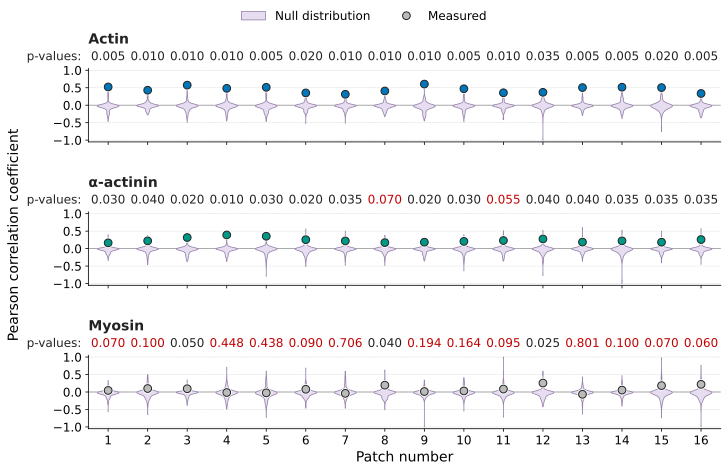

In [46]:
savepath = "../../figures/S5"
save_panel(fig, savepath, formats=("svg",))
display(SVG(filename=str(savepath + ".svg")))
plt.close(fig)